# 06 · Retraining the critical-stop model with waiting times

Notebook 04 trained a model to predict how much damage blocking a single stop does, using **static** labels (median travel times, no waiting). Notebook 05 showed that waiting roughly doubles travel times and partly reshuffles which stops matter.

Here the labels are recomputed on the **timetable**: block each of the 1,853 stops, one at a time, and re-route every stop at 7:00, 7:30, 8:00, and 8:30 with the Connection Scan Algorithm (`simulate.timetable_removal_damage`, about 4.5 minutes on 10 cores). The model is then retrained on those labels.

**Labels**
- `efficiency_loss`: static model, from notebook 04
- `tt_efficiency_loss`: timetable, blocked stop, morning peak

**Build** (adds the timetable labels and features to the dataset):
```
python -m transitshock.features data/processed/lbt_20261104.gpickle --date 20261104
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold

from transitshock.build_graph import load_graph
from transitshock.features import FEATURES, TT_FEATURES
from transitshock.load_gtfs import load_feed
from transitshock.model import MODELS, compare, out_of_fold_predictions, score, spatial_groups
from transitshock.scenario import timetable_baseline, timetable_impact
from transitshock.timetable import build_timetable

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

df = pd.read_csv(PROCESSED / "lbt_20261104_dataset.csv", index_col="node")
groups = spatial_groups(df)  # 10 neighborhoods, same as notebook 04
STATIC, TT = "efficiency_loss", "tt_efficiency_loss"
df[[STATIC, TT]].describe().round(5)

,efficiency_loss,tt_efficiency_loss
count,1853.00000,1853.00000
mean,0.00241,0.00346
std,0.00110,0.00162
min,0.00021,0.00000
25%,0.00166,0.00232
50%,0.00218,0.00317
75%,0.00290,0.00431
max,0.01013,0.01243


## 1. How different are the two labels?

Spearman between static and timetable damage: 0.66
Top 5% (93 stops): 39 are critical under both


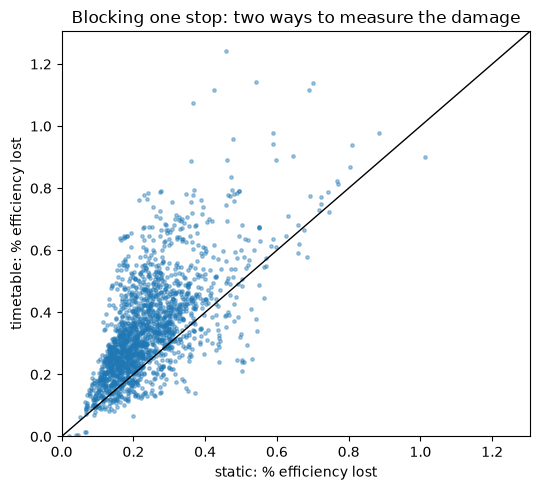

In [2]:
rho = df[[STATIC, TT]].corr(method="spearman").iloc[0, 1]
k = int(round(0.05 * len(df)))
overlap = len(set(df.nlargest(k, STATIC).index) & set(df.nlargest(k, TT).index))
print(f"Spearman between static and timetable damage: {rho:.2f}")
print(f"Top 5% ({k} stops): {overlap} are critical under both")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(100 * df[STATIC], 100 * df[TT], s=6, alpha=0.4)
lim = [0, 100 * df[[STATIC, TT]].max().max() * 1.05]
ax.plot(lim, lim, color="black", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="static: % efficiency lost", ylabel="timetable: % efficiency lost",
       title="Blocking one stop: two ways to measure the damage")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_labels_static_vs_timetable.png", dpi=150)

In [3]:
# Which stops matter a lot more once waiting counts?
ranks = pd.DataFrame({
    "name": df["name"],
    "static rank": df[STATIC].rank(ascending=False).astype(int),
    "timetable rank": df[TT].rank(ascending=False).astype(int),
    "trips/day": df["trips_per_day"].astype(int),
    "routes": df["n_routes"].astype(int),
})
ranks["rank change"] = ranks["static rank"] - ranks["timetable rank"]
print("Biggest risers (more critical with waiting):")
display(ranks.nlargest(10, "rank change"))
print("Correlation of rank change with trips/day:", round(ranks[["rank change", "trips/day"]].corr("spearman").iloc[0, 1], 2))

Biggest risers (more critical with waiting):


,name,static rank,timetable rank,trips/day,routes,rank change
node,,,,,,
lbt:0791,Atlantic & 31st NW,1418,107,118,3,1311
lbt:0079,Anaheim & Caspian NW,1626,329,103,3,1297
lbt:0081,Santa Fe & Cowles NE,1589,303,103,3,1286
lbt:0732,Atlantic & Columbia NE,1495,209,118,3,1286
lbt:0792,Atlantic & Columbia SW,1402,117,118,3,1285
lbt:0104,Santa Fe & Anaheim NE,1595,312,103,3,1283
lbt:0733,Atlantic & 31st NE,1454,179,118,3,1275
lbt:0082,Santa Fe & 16th NE,1484,246,103,3,1238
lbt:0083,Santa Fe & PCH NE,1516,280,67,2,1236


Correlation of rank change with trips/day: 0.47


## 2. Does the static model still work? Does retraining help?

Every number below is computed on held-out neighborhoods (spatial cross-validation), scored against the **timetable** labels.

In [4]:
%%time
results = compare(df, target=TT, groups=groups)
static_model = out_of_fold_predictions(df, MODELS["random_forest"], target=STATIC, groups=groups)
results.loc["static-trained random forest"] = score(df[TT], static_model)
results.loc["static label itself (exact, slow)"] = {**score(df[TT], df[STATIC].to_numpy()), "r2": np.nan}
results.round(3)

CPU times: user 1min 4s, sys: 1min 12s, total: 2min 17s
Wall time: 18.9 s


,r2,spearman,top5_overlap
heuristic: betweenness,NaN,0.538,0.258
heuristic: trips_per_day,NaN,0.376,0.118
heuristic: n_routes,NaN,0.304,0.011
heuristic: harmonic_in,NaN,0.431,0.172
heuristic: bypass_gap_m,NaN,0.063,0.065
heuristic: stranded_share,NaN,0.041,0.172
model: ridge,-6.390,0.630,0.441
model: random_forest,0.581,0.725,0.602
model: gradient_boosting,0.578,0.731,0.591
static-trained random forest,-0.079,0.592,0.387


## 3. Do timetable-aware features help?

Candidates (`features.timetable_features`, about 0.7 s):
- `am_departures`: buses leaving the stop from 7–9 AM
- `tt_harmonic_in` / `tt_harmonic_out`: closeness computed from real door-to-door times

In [5]:
%%time
rows = {}
for name, feats in [("14 graph features", FEATURES), ("+ 3 timetable features", FEATURES + TT_FEATURES)]:
    for m in ["random_forest", "gradient_boosting"]:
        p = out_of_fold_predictions(df, MODELS[m], target=TT, groups=groups, features=feats)
        rows[(name, m)] = score(df[TT], p)
pd.DataFrame(rows).T.round(3)

CPU times: user 1min 55s, sys: 2min 15s, total: 4min 10s
Wall time: 32.7 s


r2  spearman  top5_overlap
14 graph features      random_forest      0.581     0.725         0.602
                       gradient_boosting  0.578     0.731         0.591
+ 3 timetable features random_forest      0.575     0.708         0.591
                       gradient_boosting  0.560     0.711         0.559

## 4. What does the retrained model rely on?

CPU times: user 25.7 s, sys: 4.36 s, total: 30.1 s
Wall time: 22 s


betweenness       0.379
trips_per_day     0.373
dist_center_km    0.080
stranded_share    0.075
harmonic_out      0.015
harmonic_in       0.013
bypass_gap_m      0.013
pagerank          0.007
n_routes          0.004
walk_degree       0.001
nearest_stop_m    0.001
is_terminus       0.000
transit_in       -0.000
transit_out      -0.000
dtype: float64

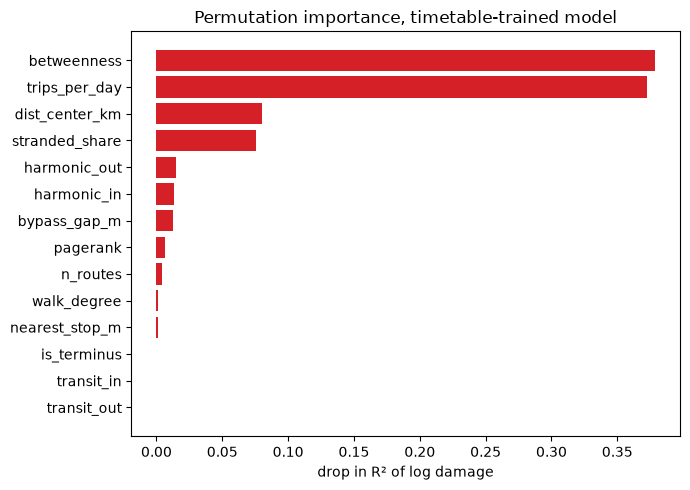

In [6]:
%%time
X, y = df[FEATURES].to_numpy(), np.log(df[TT].to_numpy())
importances = []
for train, test in GroupKFold(5).split(X, y, groups):
    model = clone(MODELS["random_forest"]).fit(X[train], y[train])
    importances.append(permutation_importance(model, X[test], y[test], n_repeats=10, random_state=0).importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color="#D62028")
ax.set(title="Permutation importance, timetable-trained model", xlabel="drop in R² of log damage")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_feature_importance_timetable.png", dpi=150)
importance.sort_values(ascending=False).round(3)

## 5. The practical test: block the top 10

Pick 10 stops four ways, block them together in the morning peak, and measure the damage on the timetable. A better ranking finds a more damaging set.

In [7]:
%%time
G = load_graph(PROCESSED / "lbt_20261104.gpickle")
tt = build_timetable(load_feed(ROOT / "data" / "raw" / "lbt", "20261104"), "lbt", G)
am = timetable_baseline(tt)
tt_model = out_of_fold_predictions(df, MODELS["random_forest"], target=TT, groups=groups)
picks = {
    "10 busiest stops": df.nlargest(10, "trips_per_day").index,
    "static-trained model's top 10": df.index[np.argsort(-static_model)[:10]],
    "timetable-trained model's top 10": df.index[np.argsort(-tt_model)[:10]],
    "true top 10 (timetable labels)": df.nlargest(10, TT).index,
}
rows = {}
for name, stops in picks.items():
    s, _ = timetable_impact(am, blocked_stops=list(stops))
    rows[name] = {"efficiency change %": 100 * s["efficiency_change"], "stops cut off": s["stops_cut_off"],
                  "stops slower": s["stops_slower"], "+ mean minutes": s["mean_time_after_min"] - s["mean_time_before_min"]}
pd.DataFrame(rows).T.round(2)

CPU times: user 14.1 s, sys: 618 ms, total: 14.7 s
Wall time: 4.28 s


,efficiency change %,stops cut off,stops slower,+ mean minutes
10 busiest stops,-2.53,0.0,111.0,0.74
static-trained model's top 10,-5.78,44.0,395.0,0.20
timetable-trained model's top 10,-5.37,0.0,899.0,3.06
true top 10 (timetable labels),-7.64,1.0,1083.0,5.36


## 6. Greedy search: the worst combination

Ranking stops one at a time ignores how blockages interact. **Greedy search** (`simulate.greedy_blocking`) picks stops one by one, each time taking the stop that adds the most damage *given the ones already blocked*. Candidates are the timetable model's top 40 plus the static model's top 15. The lazy "CELF" trick only re-measures the current leader each round.

In [8]:
%%time
from transitshock.simulate import greedy_blocking

candidates = list(dict.fromkeys(df.index[np.argsort(-tt_model)[:40]].tolist()
                                + df.index[np.argsort(-static_model)[:15]].tolist()))
greedy = greedy_blocking(tt, 10, candidates)
plain_evaluations = len(candidates) * 10  # roughly what plain greedy would need
print(f"{int(greedy['evaluations'].iloc[-1])} scenarios tested (plain greedy: about {plain_evaluations})")
greedy.assign(name=df.loc[greedy["stop"], "name"].to_numpy()).round(4)

96 scenarios tested (plain greedy: about 500)
CPU times: user 1min, sys: 389 ms, total: 1min
Wall time: 14.1 s


,step,stop,extra_loss,total_loss,evaluations,name
0,1,lbt:0206,0.0124,0.0124,50,Carson & Cherry SE
1,2,lbt:0335,0.0116,0.0240,51,Carson & R/R Tracks NE
2,3,lbt:0198,0.0097,0.0337,57,Cherry & Spring NE
3,4,lbt:4101,0.0082,0.0419,61,Studebaker & Artesia NE
4,5,lbt:0266,0.0077,0.0496,73,Cherry & PCH SW
5,6,lbt:0785,0.0078,0.0574,79,Atlantic & Carson SW
6,7,lbt:1507,0.0073,0.0648,80,223rd & Grace SE
7,8,lbt:3033,0.0068,0.0716,90,Studebaker & Reservoir Hill Park NE
8,9,lbt:0255,0.0068,0.0783,91,Cherry & Wardlow SW
9,10,lbt:1358,0.0083,0.0866,96,Lakewood & Spring NE


In [9]:
s, _ = timetable_impact(am, blocked_stops=greedy["stop"].tolist())
rows["greedy search"] = {"efficiency change %": 100 * s["efficiency_change"], "stops cut off": s["stops_cut_off"],
                         "stops slower": s["stops_slower"], "+ mean minutes": s["mean_time_after_min"] - s["mean_time_before_min"]}
pd.DataFrame(rows).T.round(2)

,efficiency change %,stops cut off,stops slower,+ mean minutes
10 busiest stops,-2.53,0.0,111.0,0.74
static-trained model's top 10,-5.78,44.0,395.0,0.20
timetable-trained model's top 10,-5.37,0.0,899.0,3.06
true top 10 (timetable labels),-7.64,1.0,1083.0,5.36
greedy search,-8.52,46.0,1272.0,3.10


## Findings

**1. Waiting changes which stops are critical.**
- Static and timetable single-stop damage correlate only moderately (Spearman 0.66). Of the true top 5% (93 stops), just 39 are critical under both.
- **The biggest risers are on frequent corridors.** Stops on Atlantic Ave (31st, Columbia) and Santa Fe Ave jump from around rank 1,400–1,600 to 107–330. They sit on 3 routes with about 100–120 trips a day.
- When waiting counts, blocking a frequent corridor forces many riders onto slower, less frequent alternatives. The static model can't see that, because it has no notion of frequency. Rank change correlates with trips/day (ρ = 0.47).

**2. The static-trained model doesn't transfer, but retraining recovers most of it.** Scored against timetable labels on held-out neighborhoods:

| Method | Spearman ρ | Top-5% found |
|---|---|---|
| trips/day alone | 0.38 | 12% |
| betweenness alone | 0.54 | 26% |
| static label itself (the exact static simulation) | 0.66 | 42% |
| static-trained random forest | 0.59 | 39% |
| **timetable-trained random forest** | **0.73** | **60%** |

The retrained model beats even the exact static simulation at predicting timetable damage, at about 1/100 of the compute.

**3. The model now relies on frequency as much as on structure.** Permutation importance is betweenness 0.38 and **trips/day 0.37**, then distance to center (0.08) and stranded share (0.08). For static damage, trips/day carried essentially no information.

**4. Timetable-aware features didn't help.** Morning-peak departures and closeness computed from real door-to-door times (`TT_FEATURES`) slightly *lowered* held-out scores (ρ 0.71 vs 0.73). Trips/day already carries the frequency signal, and the extra features mostly add noise. They stay out of the final model.

**5. The two models find different kinds of critical stops.** Blocking 10 stops in the morning peak, measured on the timetable:

| Pick 10 stops by... | Efficiency | Stops cut off | Stops slower | Avg trip |
|---|---|---|---|---|
| trips/day (busiest) | −2.5% | 0 | 111 | +0.7 min |
| static-trained model | −5.8% | **44** | 395 | +0.2 min |
| timetable-trained model | −5.4% | 0 | **899** | **+3.1 min** |
| true top 10 (timetable labels) | −7.6% | 1 | 1,083 | +5.4 min |

- **The static model finds strand points.** Blocking them cuts off small areas completely. That's a big hit to efficiency, but it barely changes the average trip for everyone else.
- **The timetable model finds frequent corridors.** Blocking them strands nobody but slows 899 stops and adds 3 minutes to the average trip.
- **Neither top 10 matches the true one** (−7.6%). Picking stops one at a time ignores how they interact, and some of the 10 overlap in what they protect.

**Takeaway:** "critical" depends on what you measure. For emergency planning ("who gets stranded?"), the static model's ranking is the right one. For everyday reliability ("whose commute gets worse?"), the timetable-trained model is better, and it's the one the app now uses by default.

**6. Greedy search finds a worse combination than any ranking.** Picking stops one by one, each time taking the one that adds the most damage given those already blocked:

| Pick 10 stops by... | Efficiency | Stops cut off | Stops slower |
|---|---|---|---|
| true single-stop top 10 | −7.6% | 1 | 1,083 |
| **greedy search** | **−8.5%** | **46** | **1,272** |

- **It mixes both kinds of critical stop.** The picks combine strand points on Cherry Ave and Studebaker with stops on frequent corridors, so the set both cuts riders off and slows everyone down.
- **Blockages compound.** A pick's extra damage sometimes *rises* from one step to the next, because a stop can matter more once its neighbors are blocked.
- **The lazy (CELF) trick saves most of the work.** It tested 96 scenarios instead of the roughly 500 that plain greedy would need, in about 14 seconds.
- **Caveat:** CELF is only guaranteed to match plain greedy when damage has diminishing returns, and here it doesn't always. So CELF's answer is a strong heuristic, not a proven worst case.

The app has this as an optional **Greedy search** toggle in the sidebar.